# Explainable Credit Risk Prediction
Independent portfolio project using UCI German Credit data (CC BY 4.0). This is not the graded Lending Club assignment. No model scores are claimed before execution.

## 1. Load the public dataset
Bad credit-risk label = 1; good credit-risk label = 0.

In [1]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import matplotlib.pyplot as plt
data = fetch_ucirepo(id=144)
X = data.data.features.copy()
y = (data.data.targets.squeeze().astype(int) == 2).astype(int)
print("Rows and features:", X.shape)
print("Class distribution:", y.value_counts().to_dict())
display(X.head())

Rows and features: (1000, 20)
Class distribution: {0: 700, 1: 300}


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


## 2. EDA and quality checks
Examine feature types, missingness, and label balance.

,dtype,missing
Attribute1,object,0
Attribute2,int64,0
Attribute3,object,0
Attribute4,object,0
Attribute5,int64,0
Attribute6,object,0
Attribute7,object,0
Attribute8,int64,0
Attribute9,object,0
Attribute10,object,0


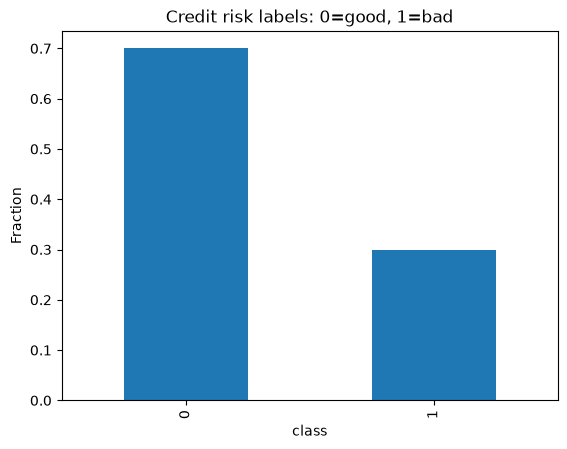

In [2]:
display(pd.DataFrame({"dtype": X.dtypes.astype(str), "missing": X.isna().sum()}))
y.value_counts(normalize=True).sort_index().plot.bar(title="Credit risk labels: 0=good, 1=bad")
plt.ylabel("Fraction")
plt.show()

## 3. Train, tune, calibrate, and evaluate
The separate `src/train.py` pipeline compares regular and class-weighted Logistic Regression and Random Forest, uses stratified five-fold CV within the training set, fits sigmoid calibration from training folds, chooses an F1 threshold using out-of-fold predictions, and evaluates only on the held-out test set. SHAP explanations are optional.

In [3]:
import sys
from pathlib import Path
root = Path.cwd()
if not (root / "src").exists():
    root = root.parent
sys.path.insert(0, str(root))
from src.train import run
report = run(output_dir=str(root / "results"), shap_enabled=False)

{
  "dataset": "UCI Statlog German Credit (CC BY 4.0)",
  "rows": 1000,
  "bad_risk_fraction": 0.3,
  "train_rows": 800,
  "test_rows": 200,
  "selected_model": "Random Forest",
  "threshold": 0.33999999999999997,
  "validation_oof_brier": 0.16119545405211672,
  "test": {
    "roc_auc": 0.8013095238095238,
    "average_precision": 0.651408220715531,
    "brier": 0.15775646550969236,
    "log_loss": 0.48206936999747,
    "precision": 0.56,
    "recall": 0.7,
    "f1": 0.6222222222222222,
    "tn": 107,
    "fp": 33,
    "fn": 18,
    "tp": 42
  },
  "warning": "Educational benchmark, not a deployment-ready lending decision system."
}


## 4. Inspect held-out results
ROC-AUC and average precision are ranking metrics; Brier/log loss assess probabilities. F1, precision, and recall use a threshold selected on training-only OOF predictions. Do not tune the method on the test results.

,Independent test
roc_auc,0.801310
average_precision,0.651408
brier,0.157756
log_loss,0.482069
precision,0.560000
recall,0.700000
f1,0.622222
tn,107.000000
fp,33.000000
fn,18.000000


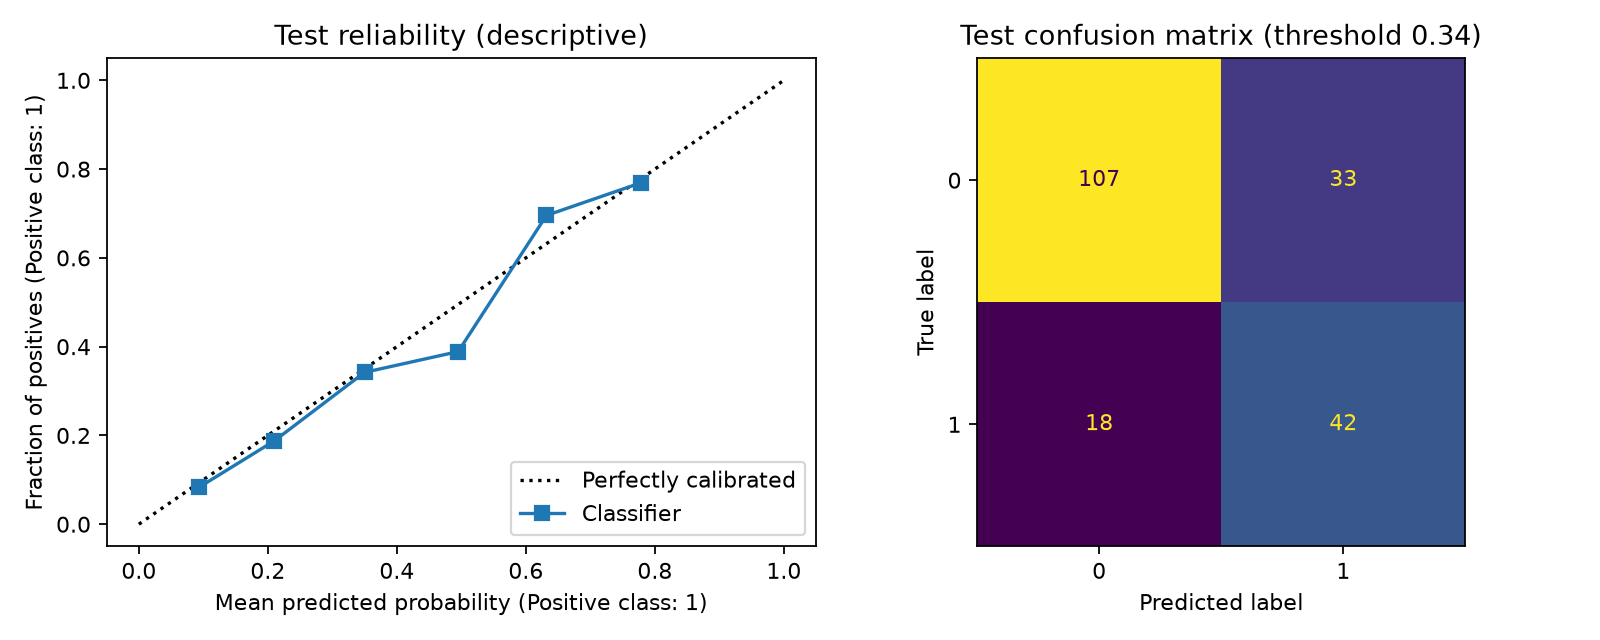

In [4]:
from IPython.display import Image, display
display(pd.DataFrame([report["test"]]).T.rename(columns={0: "Independent test"}))
display(Image(filename=str(root / "results" / "evaluation.png")))

## 5. Limitations
The data are a historical benchmark, not prospective loan defaults. Calibration and SHAP results may be unstable with few observations. Fairness, external validation, economic costs, and regulatory requirements are outside scope. SHAP describes the underlying uncalibrated model and does not establish causality.